# Fase 2 — Inferencia estadística

Material de apoyo con asistencia de IA. El grupo debe revisar y comprender el código y adoptar sus decisiones e interpretaciones. No se fabrican personas ni se afirma causalidad. La unidad es una participación de víctima lesionada registrada por PRF, no el riesgo por viaje.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'protocolo.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from common import OUT, DATA, load_data
from preparar import prepare
if not (DATA / 'victimas_modelado.joblib').exists():
    from common import RAW
    if not (RAW / 'pessoas_2017.zip').exists():
        from descargar_fuentes import main as descargar
        descargar()
    prepare()
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_colwidth', 90)
def tabla(nombre):
    return pd.read_csv(OUT / 'tables' / nombre)


## Correcciones y protocolo

Se reemplazan filas expandidas por fichas reales, se consideran víctimas del mismo accidente y se conservan faltantes sin inventar edades. Se declaran cuatro contrastes bilaterales, alfa 0,05, Holm y tres familias clásicas más GLM. Las pruebas clásicas seleccionan una víctima aleatoria por accidente: sus resultados ponderan accidentes, no todas las víctimas por igual.

In [2]:
protocolo = json.loads((ROOT / 'protocolo.json').read_text(encoding='utf8'))
display(protocolo['inferencia'])
from fase2 import main as inferir
f2 = inferir()
display(tabla('supuestos_fase2.csv'))

{'periodo': 'Solo desarrollo 2017-2023',
 'alfa': 0.05,
 'correccion': 'Holm, familia de cuatro contrastes',
 'hipotesis': ['H1: asociacion entre sexo y desenlace',
  'H2: diferencia de edad entre fallecidos y heridos',
  'H3: diferencia de letalidad entre usuarios de moto y otros',
  'H4: asociacion nocturnidad/desenlace ajustada por edad, sexo, moto y ruralidad'],
 'dependencia': 'Agrupacion por accidente; unidad independiente por accidente para contrastes clasicos y errores robustos por accidente para regresion/IC poblacion de victimas. No causalidad.'}

Fase 2 terminada: cuatro contrastes con Holm, bootstrap y agrupacion por accidente


,contraste,supuesto,resultado,decision
0,H1,Una victima por accidente; frecuencias esperadas >=5,min esperado 6226.2; sin IDs duplicados,Chi cuadrado; no requiere normalidad
1,H2,"Distribucion de edades, normalidad, dispersion e independencia por accidente","Shapiro submuestras: p fallecidos=1.71e-23, heridos=9.41e-30; Levene p=0","Mann-Whitney compara distribuciones/rangos, no solo medianas; no exige varianzas iguales"
2,H3,Muestras de accidentes disjuntos; exitos y fracasos >=5,moto muertos/vivos=8857/157587; otros=11189/185687,Prueba z dos proporciones; bootstrap de Bernoulli empiricas como contraste de IC
3,H4,Convergencia; dependencia intraccidente; forma funcional y confusores,convergio=True; accidentes=334129; rango X=9/9,"Sandwich por accidente; edad cuadratica; no garantiza ausencia de confusion, independe..."


## Hipótesis, efectos e intervalos

H1 evalúa asociación sexo/desenlace; H2 diferencia de distribuciones de edad; H3 diferencia de letalidad moto/otros entre conductores y pasajeros; H4 nocturnidad ajustada mediante GLM binomial y SE por accidente. H0 y H1 formales se muestran en la tabla. p guardado como cero indica subdesbordamiento numérico, no probabilidad exactamente cero.

,id,H0,H1,prueba,n,estadistico,gl,p,efecto,valor_efecto,IC95_bajo,IC95_alto,alcance,p_Holm,decision
0,H1,Sexo y desenlace son independientes en una victima aleatoria por accidente,Existe asociacion entre sexo y desenlace,Chi cuadrado independencia,383153,2.041346e+03,1.0,0.000000,V de Cramer,0.072991,0.070514,0.075441,Una victima aleatoria por accidente; sexo conocido; IC bootstrap multinomial,0.000000,Rechazar H0
1,H2,Distribuciones de edad iguales entre fallecidos y heridos,Las distribuciones de edad difieren,"Mann-Whitney bilateral, correccion de empates",370413,4.825353e+09,NaN,0.000000,Correlacion biserial de rangos,0.160610,0.152900,0.167941,Una victima por accidente con edad 1..110; IC bootstrap estratificado por desenlace,0.000000,Rechazar H0
2,H3,Proporcion de fallecimiento igual en usuarios de moto y otros vehiculos,Las proporciones difieren,Z bilateral de dos proporciones,363320,-4.761080e+00,NaN,0.000002,Diferencia de riesgos moto menos otros,-0.003620,-0.005094,-0.002124,Una victima por accidente; conductores/pasajeros con vehiculo conocido,0.000002,Rechazar H0
3,H4,Coeficiente de noche igual a cero condicionado a los controles,Coeficiente de noche distinto de cero,Wald z de GLM binomial; SE agrupados por accidente,494806,4.341996e+01,NaN,0.000000,Odds ratio ajustado noche frente a pleno dia,1.849499,1.798868,1.901555,Todas las victimas de desarrollo con covariables completas; dependencia dentro de acci...,0.000000,Rechazar H0


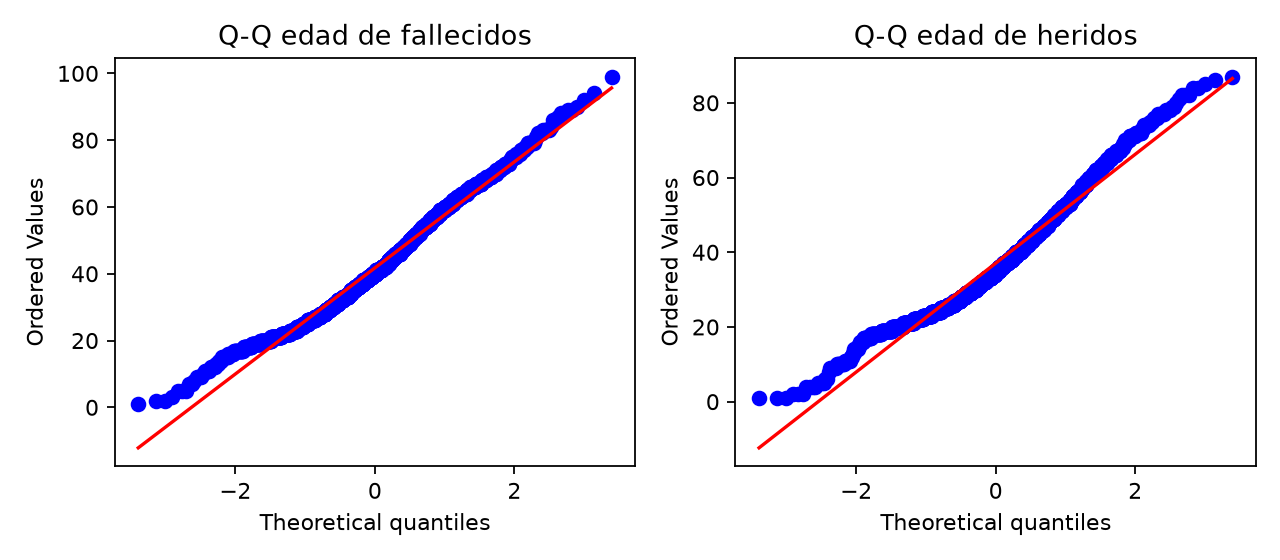

In [3]:
display(tabla('contrastes_fase2.csv'))
display(Image(filename=str(OUT / 'figures/f2_01_normalidad.png')))

Shapiro y Q-Q señalan distribución de edad no normal; se usa Mann-Whitney, que no equivale en general a comparar únicamente medianas. H1 verifica frecuencias esperadas; H3 suficientes éxitos y fracasos; el GLM verifica rango y convergencia. La independencia entre accidentes sigue siendo una aproximación.

{'efecto': -0.003619634507009681,
 'IC95_bootstrap': [-0.005093599761689422, -0.0021236062179372374],
 'IC95_clasico': [-0.005105826141055428, -0.002133442872963934],
 'razon_riesgos': 0.9363107370451302,
 'proporcion_moto': 0.05321309269183629,
 'proporcion_otros': 0.056832727198845974,
 'replicas': 5000}

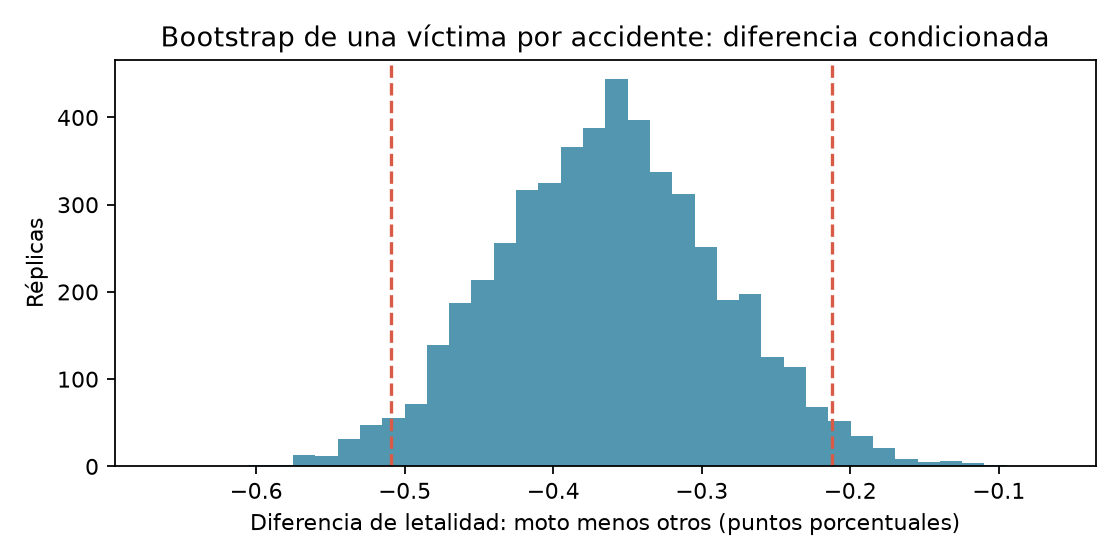

,variable,beta,SE_cluster_accidente,p,OR,OR_IC95_bajo,OR_IC95_alto
0,intercepto,-4.585110,0.044077,0.000000e+00,0.010203,0.009358,0.011123
1,noche,0.614915,0.014162,0.000000e+00,1.849499,1.798868,1.901555
2,edad_por_10,0.090893,0.016910,7.648627e-08,1.095151,1.059451,1.132055
3,edad_por_10_cuadrado,0.006605,0.001862,3.904798e-04,1.006627,1.002959,1.010308
4,masculino,0.551777,0.015653,3.434660e-272,1.736336,1.683874,1.790432
5,usuario_moto,0.125337,0.015885,3.019444e-15,1.133531,1.098782,1.169378
6,peaton,1.745381,0.021670,0.000000e+00,5.728084,5.489895,5.976607
7,rural,0.874766,0.015809,0.000000e+00,2.398313,2.325139,2.473790
8,anio_desde_2017,-0.001446,0.003464,6.764257e-01,0.998555,0.991799,1.005358


In [4]:
display(f2['bootstrap'])
display(Image(filename=str(OUT / 'figures/f2_02_bootstrap.png')))
display(tabla('regresion_logistica_inferencial.csv'))

## Interpretación

Los cuatro contrastes rechazan H0 con Holm, con efectos de magnitudes diferentes. La pequeña diferencia negativa para moto se refiere a víctimas ya lesionadas registradas y NO demuestra menor riesgo por viaje. Nocturnidad conserva OR ajustado próximo a 1,85, sin demostrar causa. Los IC son marginales; faltan exposición y confusores, y hay selección por registro y covariables completas. Se conservan variables plausibles para predicción sin seleccionarlas solo por valores p.